In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/28/2022
# version ='1.0'

# Demo: Further Experiments on Solving A Small Linear Programming by  Primal-Dual Interior-Point Method

In book-convex-2004, the primal-dual interior-point method was applied to the following linear programming in inequality form,
\begin{equation}
\begin{array}{rl}
\text{minimize} & c^T  x \\
\text{subject} & Ax \preceq b \\
\end{array}
\end{equation}
where $A\in R^{m\times n}$.

In the previous demo, a method to generate $A, b, c$ randomly in such a way that the problem is strictly primal and dual feasible with optimal value $p^*=1$ has been discussed.

The primal-dual interior method is repeated here,


### Primal-dual interior-point method

1. given the convex problem like
\begin{equation}
\begin{array}{rcl}
\text{minimize} & f_0(x) & \\
\text{subject to} & f_i(x)\leq 0 & i=1,2,...,m\\
& Ax=b & \\
\end{array}
\end{equation}
1. given $x$ that satisfies $f_1(x)<0, ..., f_m(x)<0, \lambda\succeq 0, \mu>1, \epsilon_{feas}>0, \epsilon>0$
1. Repeat:
\begin{enumerate}
\item Determine $t$ by setting $t\leftarrow \mu m /\hat{\eta}$
\item Compute the primal-dual search direction $\Delta y_{pd}$
\item Line search and update by determine step length $s>0$ and set $y\leftarrow y+s\Delta y_{pd}$
\end{enumerate}
Until $\parallel r_{pri}\parallel_2\leq \epsilon_{feas}$, $\parallel r_{dual}\parallel_2\leq \epsilon_{feas}$ and $\hat{\eta}\leq \epsilon$


When applying the Primal-Dual Interior-Point Method to the above linear programming problem, the primal-dual search direction $\Delta y_{pd}=(\Delta x_{pd}, \Delta \lambda_{pd})$ is defined as the solution of the following equation,
\begin{equation}
\begin{array}{rccl}
H & 
\left[
\begin{array}{c}
\Delta x_{pd} \\
\Delta \lambda_{pd} \\
\end{array}
\right] &  = & -
\left[
\begin{array}{c}
\gamma_{dual} \\
\gamma_{cent} \\
\end{array}
\right]
\end{array}
\end{equation}

where

\begin{equation}
\begin{array}{rcl}
H & = & \left[\begin{array}{cc}
\nabla^2 f_0(x)+\displaystyle{\sum_{i=0}^m}\lambda_i\nabla^2f_i(x) & Df(x)^T \\
-diag(\lambda)Df(x) & -diag(f(x)) 
\end{array} \right] \\
f_0(x) & = & c^Tx \\
f(x) & = &  \left[\begin{array}{c}
f_1(x) \\
f_2(x) \\
\cdots \\
f_m(x) \\
\end{array} \right] = \left[\begin{array}{c}
a_1^T x-b \\
a_2^T x-b \\
\cdots \\
a_m^T x-b \\
\end{array} \right]=Ax-b \\
\nabla f_0(x) & = & c \\
Df(x) & = & \left[\begin{array}{c}
\nabla f_1(x)^T \\
\nabla f_2(x)^T \\
\cdots \\
\nabla f_m(x)^T \\
\end{array} \right] = A \\
\nabla^2 f_0(x) & = & \mathbf{0}_{n\times n} \\
\nabla^2f_i(x) & = & \mathbf{0}_{n\times n} \\
\end{array}
\end{equation}

After some calculations,

\begin{equation}
\begin{array}{rcl}
H & = & \left[\begin{array}{rcc}
\mathbf{0}_{n\times n} & A^T \\
-diag(\lambda)A & -diag(Ax-b) \\
\end{array} \right] \\
r_{dual} & = & c + A^T \lambda \\
r_{center} & = & -diag(\lambda) (Ax-b)-\frac{1}{t} \mathbf{1}_m \\
\end{array}
\end{equation}

The calculation of the surrogate duality gap ($\hat{\eta}(x,\lambda)$), and the line search for step is the same as described in section 11.7.3 in book-convex-2004.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

$f_0(x)=c^T x$

$\nabla f_0(x)=c$

$\nabla^2 f_0(x)=0_{n\times n}$

In [3]:
def my_f_0(x, t, A, b, c):
    """
    $f_0(x)=c^Tx$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return (c.T @ x).item()


def my_f_0_feasible(x, t, A, b, c):
    return True


def my_gradient_f_0(x, t, A, b, c):
    """
    $\nabla f_0(x)=c$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return c


def my_hessian_f_0(x, t, A, b, c):
    """
    $\nabla^2 f_0(x)=0$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return np.zeros((len(x), len(x)))

Generate model parameter, A, b, c with optimal point xp, start point x0 with optimal value equal to p ($p_+$), and
     duality gap equal to duality_gap ($d_+$)
     
Refer to Algorithm-2 in the FlexibleLecture note

In [4]:
def get_A_b(m, n, p_asterisk, nI, duality_gap):
    """
    Generate model parameter, A, b, c with optimal point xp, start point x0 with optimal value equal to p ($p_+$), and
     duality gap equal to duality_gap ($d_+$)
    Refer to Algorithm-2 in the FlexibleLecture note
    :param m:
    :param n:
    :param p_asterisk:
    :param nI: $\mathcal{I}$, the number of inequality constraints activation, i.e. $|I[Ax^*=b]|_1=|\lambda\neq 0|$
    :param duality_gap:
    :return:
    """
    if nI > m or nI < 0:
        raise RuntimeError('nI should be equal to or less than m, and greater than zero.')

    x_asterisk_init = -np.random.rand(n, 1)
    A = np.random.rand(m, n)
    b = np.zeros((m, 1))

    # In the experiment, set $\lambda [0: (m - nI)]=0, \lambda [m - nI:]>0$
    lambda_ = np.random.rand(m, 1)
    if m - nI > 0:
        lambda_[0:m - nI, 0] = 0

    c = -A.T @ lambda_
    x0 = -1 * np.ones((n, 1))

    f_min = my_f_0(x_asterisk_init, None, None, None, c)
    if not f_min > 0:
        raise RuntimeError('it is preferred to have optimal value > 0 for experiment.')

    # to scale the parameters so that the primal value = p
    beta = p_asterisk / f_min
    x_asterisk = x_asterisk_init * beta

    f_min = my_f_0(x_asterisk, None, None, None, c)
    # print('fmin={}, p ={}'.format(f_min, p))

    # to rescale C, A, xp so that the dual gap at the x0 is dual_gap
    f_x0 = c.T @ x0
    gamma = (duality_gap + p_asterisk) / f_x0
    c = gamma * c
    A = gamma * A
    x_asterisk = x_asterisk / gamma

    Ax = A @ x_asterisk
    eta = 1
    for i, lambda_i in enumerate(lambda_):
        if lambda_i > 0:
            b[i] = Ax[i]
        else:
            b[i] = Ax[i] + np.random.rand(1, 1) * eta

    if not (np.linalg.matrix_rank(A) == min(m, n)):
        raise RuntimeError('A is not full rank?')

    if not np.allclose(A @ x_asterisk, b) and not (np.all(A @ x_asterisk <= b)):
        raise RuntimeError('problem is not feasible? A @ x <=b')

    if not np.all(A @ x0 <= b):
        raise RuntimeError('start point should be feasible at Ax <= b')

    if not (np.allclose(c + A.T @ lambda_, 0)):
        raise RuntimeError('problem is not feasible? c + A.T @ lambda == 0')

    if not (np.allclose(lambda_.T @ (A @ x_asterisk - b), 0)):
        raise RuntimeError('problem is not feasible? lambda.T @ (A @ x - b) == 0')

    if not np.allclose(f_min - p_asterisk, 0):
        raise RuntimeError('It is required to have f_min = p')

    if not np.allclose(my_f_0(x0, None, A, b, c) - p_asterisk, duality_gap):
        raise RuntimeError('It is required to have a duality gap = {}'.format(duality_gap))

    return A, b, c, x_asterisk, x0

solve the primal-dual search direction by direct matrix inversion

In [5]:
def my_primal_dual_search_direction(x, lambda_, t, A, b, c):
    """
    solve the primal-dual search direction by direct matrix inversion
    :param x:
    :param lambda_:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    m, n = A.shape
    H = np.block([[np.zeros((n, n)), A.T], [-np.diag(np.squeeze(lambda_)) @ A, -np.diag(np.squeeze(A @ x - b))]])
    r_dual = my_gradient_f_0(x, t, A, b, c) + A.T @ lambda_
    r_cent = -np.diag(np.squeeze(lambda_)) @ (A @ x - b) - 1 / t * np.ones((m, 1))
    r = np.block([[r_dual], [r_cent]])

    cond = np.linalg.cond(H)
    if cond < 1e30:
        delta_y_pd = np.linalg.inv(H) @ (-r)
        delta_x_pd = delta_y_pd[0:n]
        delta_lambda_pd = delta_y_pd[n:]
        return delta_x_pd, delta_lambda_pd
    else:
        raise RuntimeError('H is not invertible.')

The standard backtracking line search method

Refer to section 11.7.3 in the textbook

In [6]:
def backtracking_line_search(x, lambda_, delta_x_pd, delta_lambda_pd, alpha, beta, t, args):
    """
    the standard backtracking line search method
    Refer to section 11.7.3 in the textbook
    :param x:
    :param lambda_:
    :param delta_x_pd:
    :param delta_lambda_pd:
    :param alpha:
    :param beta:
    :param t:
    :param args:
    :return:
    """
    A, b, c = args
    m, n = A.shape
    tmp = [-lambda_[i][0] / delta_lambda_pd[i][0] if delta_lambda_pd[i][0] < 0 else 1 for i in range(m)]
    s_max = min(1, np.min(tmp))
    s = 0.99 * s_max
    while True:
        x_next = x + s * delta_x_pd
        if np.all(A @ x_next - b < 0):
            break
        else:
            s = beta * s

    r_dual_current = my_gradient_f_0(x, t, A, b, c) + A.T @ lambda_
    r_cent_current = -np.diag(np.squeeze(lambda_)) @ (A @ x - b) - 1 / t * np.ones((m, 1))
    r_current = np.block([[r_dual_current], [r_cent_current]])
    r_current_norm = np.linalg.norm(r_current)
    while True:
        x_next = x + s * delta_x_pd
        lambda_next = lambda_ + s * delta_lambda_pd
        r_dual_next = my_gradient_f_0(x_next, t, A, b, c) + A.T @ lambda_next
        r_cent_next = -np.diag(np.squeeze(lambda_next)) @ (A @ x_next - b) - 1 / t * np.ones((m, 1))
        r_next = np.block([[r_dual_next], [r_cent_next]])
        r_next_norm = np.linalg.norm(r_next)

        if r_next_norm <= (1 - alpha * s) * r_current_norm:
            break
        else:
            s = beta * s

    return s

plot the progress of the convergence of $\hat{\eta}$ and $r_{feas}$

In [7]:
def plot_convergence_speed(m, n, mu, seed, max_iteration=100):
    """
    plot the progress of the convergence of $\hat{\eta}$ and $r_{feas}$
    :param m:
    :param n:
    :param mu:
    :param seed:
    :return:
    """
    plt.figure(figsize=(12, 6))
    ax1 = plt.subplot(3, 1, 1)
    ax2 = plt.subplot(3, 1, 2)
    ax3 = plt.subplot(3, 1, 3)

    if m < n:
        raise RuntimeError('it requires m > n')

    r_pri = 0

    lambda_zeros_num = [0, int(m / 4), int(m / 2), int(3 * m / 4), m - 1]  # [int(3 * m / 4)]#, m-1] #
    for z_i, zero_num in enumerate(lambda_zeros_num):
        nI = m - zero_num
        np.random.seed(seed)

        p_asterisk = 1
        duality_gap = 100
        A, b, c, _, x0 = get_A_b(m, n, p_asterisk, nI, duality_gap)

        alpha = 0.01
        beta = 0.5
        epsilon = 1e-8
        epsilon_feas = 1e-8

        lambda_0 = -1 / (A @ x0 - b)
        eta_0 = -(lambda_0.T @ (A @ x0 - b)).item()
        t = m / eta_0

        # save the statistics
        eta_s = [eta_0]
        r_dual_0 = my_gradient_f_0(x0, t, A, b, c) + A.T @ lambda_0
        r_dual_0_norm = np.linalg.norm(r_dual_0)
        r_feas = [np.sqrt(r_pri ** 2 + r_dual_0_norm ** 2)]
        f0_s = [my_f_0(x0, t, A, b, c)]

        eta = eta_0
        x = x0
        lambda_ = lambda_0
        args = (A, b, c)
        iteration = 0
        success = False
        while True:
            t = mu * m / eta
            delta_x_pd, delta_lambda_pd = my_primal_dual_search_direction(x, lambda_, t, A, b, c)
            s = backtracking_line_search(x, lambda_, delta_x_pd, delta_lambda_pd, alpha, beta, t, args)
            x_next = x + s * delta_x_pd
            lambda_next = lambda_ + s * delta_lambda_pd
            x = x_next
            lambda_ = lambda_next

            eta = -(lambda_.T @ (A @ x - b)).item()
            r_dual = my_gradient_f_0(x, t, A, b, c) + A.T @ lambda_
            r_dual_norm = np.linalg.norm(r_dual)

            # save the statistics
            eta_s.append(eta)
            r_feas.append(np.sqrt(r_pri ** 2 + r_dual_norm ** 2))
            f0_s.append(my_f_0(x, t, A, b, c))

            # print('Info: iteration={}, |r_dual|={}, eta={}, s={}'.format(iteration, r_dual_norm, eta, s))
            iteration += 1
            if r_dual_norm < epsilon_feas and eta < epsilon:
                success = True
                break
            if iteration > max_iteration:
                break

        if success:
            print('Info: final fp={}'.format(my_f_0(x, t, A, b, c)))

        ax1.semilogy(eta_s, marker='o', linestyle='solid', fillstyle='none',
                     label=r'$|I[Ax-b=0]|_1$={}'.format(m - zero_num))
        ax1.xaxis.set_major_locator(MultipleLocator(1))
        ax1.set_ylabel(r'$\eta$')
        ax1.grid()
        ax1.legend()

        ax2.semilogy(r_feas, marker='o', linestyle='solid', fillstyle='none',
                     label=r'$|I[Ax-b=0]|_1$={}'.format(m - zero_num))
        ax2.xaxis.set_major_locator(MultipleLocator(1))
        ax2.set_ylabel(r'$\gamma_{feas}$')
        ax2.set_xlabel('iteration')
        ax2.grid()
        ax2.legend()

        ax3.semilogy(f0_s, marker='o', linestyle='solid', fillstyle='none',
                     label=r'$|I[Ax-b=0]|_1$={}'.format(m - zero_num))
        ax3.xaxis.set_major_locator(MultipleLocator(1))
        ax3.set_ylabel(r'$f_0(x)$')
        ax3.set_xlabel('iteration')
        ax3.grid()
        ax3.legend()

    plt.show()

Info: final fp=1.0000000018815178
Info: final fp=1.000000001575963
Info: final fp=1.0000000045512512
Info: final fp=1.0000000017237198
Info: final fp=1.0000000007352305


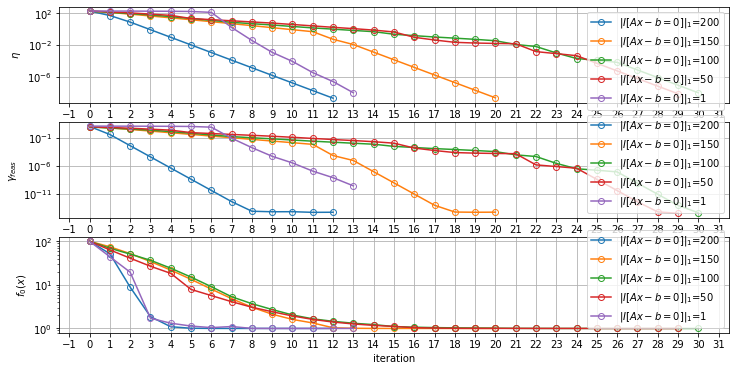

In [8]:
if __name__ == "__main__":
    plot_convergence_speed(m=200, n=100, mu=10, seed=1)